# **NGHIÊN CỨU BỘ DỮ LIỆU FLORA: GENAI-ASSISTED INFORMATION PROBLEM SOLVING**
**Tài liệu nền:** Li et al. (2026) *Scientific Data*; [12] Cai & Tian (2025); [17] Dai et al. (2025); [32]/[33] Li et al. (2025)

---

## MỤC LỤC
1. [Giới thiệu và bối cảnh bộ dữ liệu](#1.-Giới-thiệu-và-bối-cảnh-bộ-dữ-liệu)
2. [Khai báo thư viện và đọc dữ liệu](#2.-Khai-báo-thư-viện-và-đọc-dữ-liệu)
3. [Đối chiếu số liệu với bài báo & Kiểm tra chất lượng dữ liệu](#3.-Đối-chiếu-số-liệu-với-bài-báo-&-Kiểm-tra-chất-lượng-dữ-liệu)
4. [Cấu trúc dữ liệu và sơ đồ liên kết (Data Schema)](#4.-Cấu-trúc-dữ-liệu-và-sơ-đồ-liên-kết-(Data-Schema))
5. [Bảng từ điển dữ liệu (Data Dictionary) & Codebook Tiếng Việt](#5.-Bảng-từ-điển-dữ-liệu-(Data-Dictionary)-&-Codebook-Tiếng-Việt)
6. [Bảng thuật ngữ chuyên ngành (Glossary)](#6.-Bảng-thuật-ngữ-chuyên-ngành-(Glossary))
7. [Thống kê mô tả cơ bản & Trực quan hóa](#7.-Thống-kê-mô-tả-cơ-bản-&-Trực-quan-hóa)
8. [Đề xuất các câu hỏi nghiên cứu (Research Questions)](#8.-Đề-xuất-các-câu-hỏi-nghiên-cứu-(Research-Questions))

---

# 1. Giới thiệu và bối cảnh bộ dữ liệu

Bộ dữ liệu **FLoRA Open Data IPS** ghi nhận toàn bộ quá trình **Giải quyết vấn đề thông tin có hỗ trợ của GenAI (GenAI-Assisted Information Problem Solving - IPS)** trong bối cảnh giáo dục đại học thực tế (môn học sau đại học *FIT5145 Foundations of Data Science*, Đại học Monash, Úc, học kỳ `2024S2`).

* **Nền tảng thu thập:** Hệ thống **FLoRA** tích hợp trên Moodle gồm 3 vùng (*Navigation Zone*, *Reading Zone*, *Tools Zone*) với công cụ đọc–ghi chú, công cụ soạn thảo và chatbot **GPT-4o** (qua OpenAI API, không tìm kiếm web trực tiếp, được thiết kế để hỗ trợ dẫn dắt chứ không viết hộ bài).
* **Quy trình thu thập 4 giai đoạn (Phases):**
  1. **Phase 1 (Pre-task Survey):** Khảo sát nhân khẩu học (`5.5`) và kiến thức nền DS/GenAI (`5.6`).
  2. **Phase 2 (Training):** Làm quen giao diện và công cụ FLoRA.
  3. **Phase 3 (Main Task - 2 tuần):** Viết đề xuất dự án khoa học dữ liệu (chiếm 15% điểm môn học), thu thập log hội thoại (`5.1`), dấu vết tương tác hệ thống (`5.2`), log gõ phím viết bài (`5.3`), log đánh dấu/ghi chú (`5.8`) và bài nộp kèm điểm số (`5.4`).
  4. **Phase 4 (Post-task Survey):** Khảo sát cảm nhận và trải nghiệm sử dụng nền tảng (`5.7`).
* **Quy trình lọc mẫu (519 $\rightarrow$ 454 $\rightarrow$ 275 sinh viên):** Loại trừ sinh viên không dùng FLoRA (65), thiếu bài nộp trên FLoRA, viết bài ngoài hệ thống, không chat hoặc chỉ chat 1 lượt ngoài lề, và có độ tương đồng ngữ nghĩa (`text-embedding-3-small`) giữa bản FLoRA và bản nộp Moodle $< 0.85$.

# 2. Khai báo thư viện và đọc dữ liệu

In [5]:
import os
import glob
import json
import ast
import warnings
warnings.filterwarnings('ignore')

import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
import matplotlib.patches as patches

# Cấu hình hiển thị giống chuẩn OULAD
sns.set_theme(style="whitegrid")
plt.rcParams['font.sans-serif'] = 'DejaVu Sans'
plt.rcParams['axes.unicode_minus'] = False
pd.set_option('display.max_columns', None)
pd.set_option('display.max_colwidth', 100)

DATA_DIR = "data_raw"
CACHE_DIR = "data_processed"
os.makedirs(CACHE_DIR, exist_ok=True)

# 1. Đọc các bảng kích thước vừa và nhỏ
ids_275      = pd.read_csv(f"{DATA_DIR}/275_student_ids.csv")
dialogue     = pd.read_excel(f"{DATA_DIR}/5.1_dialogue data.xlsx")
writing_log  = pd.read_excel(f"{DATA_DIR}/5.3_writing_log.xlsx")
proposal     = pd.read_excel(f"{DATA_DIR}/5.4_proposal_and_score.xlsx")
pre_bio      = pd.read_excel(f"{DATA_DIR}/5.5_pre-task_biographic_survey.xlsx")
pre_know     = pd.read_excel(f"{DATA_DIR}/5.6_pre-prio_knowledge_survey.xlsx")
post_survey  = pd.read_excel(f"{DATA_DIR}/5.7_post-experience_using_platform_survey.xlsx")
annotation   = pd.read_excel(f"{DATA_DIR}/5.8_annotation_log_cleaned.xlsx")

# 2. Đọc ĐỦ TẤT CẢ CÁC SHEET của 2 file 5.2_system_interaction_trace_data (có cache để chạy lại nhanh)
trace_cache_path = f"{CACHE_DIR}/5.2_trace_all.pkl"
trace_sheet_stats = []

if os.path.exists(trace_cache_path):
    print("Đang đọc 5.2_trace_all từ cache (.pkl)...")
    trace_all = pd.read_pickle(trace_cache_path)
    if os.path.exists(f"{CACHE_DIR}/5.2_sheet_stats.csv"):
        trace_sheet_stats = pd.read_csv(f"{CACHE_DIR}/5.2_sheet_stats.csv").to_dict('records')
else:
    trace_dfs = []
    for fpath in sorted(glob.glob(f"{DATA_DIR}/5.2_*.xlsx")):
        fname = os.path.basename(fpath)
        xl = pd.ExcelFile(fpath)
        for s in xl.sheet_names:
            print(f"  -> Đang đọc {fname} | Sheet: '{s}' ...")
            df_s = pd.read_excel(xl, sheet_name=s)
            trace_sheet_stats.append({
                "Tên file": fname,
                "Sheet": s,
                "Số dòng": len(df_s),
                "Số cột": len(df_s.columns),
                "Số user_id": df_s['user_id'].nunique()
            })
            trace_dfs.append(df_s)
    trace_all = pd.concat(trace_dfs, ignore_index=True)
    trace_all.to_pickle(trace_cache_path)
    pd.DataFrame(trace_sheet_stats).to_csv(f"{CACHE_DIR}/5.2_sheet_stats.csv", index=False)

print("Đã tải xong toàn bộ bộ dữ liệu FLoRA!")

  -> Đang đọc 5.2_system_interaction_trace_data_1.xlsx | Sheet: 'Result 1' ...
  -> Đang đọc 5.2_system_interaction_trace_data_1.xlsx | Sheet: 'Result 2' ...
  -> Đang đọc 5.2_system_interaction_trace_data_1.xlsx | Sheet: 'Result 3' ...
  -> Đang đọc 5.2_system_interaction_trace_data_1.xlsx | Sheet: 'Result 4' ...
  -> Đang đọc 5.2_system_interaction_trace_data_2.xlsx | Sheet: 'Result 1' ...
  -> Đang đọc 5.2_system_interaction_trace_data_2.xlsx | Sheet: 'Result 2' ...
  -> Đang đọc 5.2_system_interaction_trace_data_2.xlsx | Sheet: 'Result 3' ...
  -> Đang đọc 5.2_system_interaction_trace_data_2.xlsx | Sheet: 'Result 4' ...
Đã tải xong toàn bộ bộ dữ liệu FLoRA!


# 3. Đối chiếu số liệu với bài báo & Kiểm tra chất lượng dữ liệu

### 3.1. Đối chiếu Số file, Số dòng, Số cột và Số sinh viên với Bài báo (Table 7–14)

In [6]:
# Nếu có thống kê từng sheet của 5.2 thì hiển thị
if len(trace_sheet_stats) > 0:
    print("--- CHI TIẾT CÁC SHEET TRONG FILE 5.2_system_interaction_trace_data ---")
    display(pd.DataFrame(trace_sheet_stats))

valid_ids = set(ids_275['user_id'].unique())

datasets = {
    "275_student_ids.csv":                           (ids_275,     275,     275, 1,  "Cohort IDs"),
    "5.1_dialogue data.xlsx":                        (dialogue,    3542,    275, 7,  "Table 7"),
    "5.2_system_interaction_trace_data (1 & 2)":     (trace_all,   7542124, 275, 7,  "Table 8"),
    "5.3_writing_log.xlsx":                          (writing_log, 496733,  275, 4,  "Table 9"),
    "5.4_proposal_and_score.xlsx":                   (proposal,    275,     275, 3,  "Table 11"),
    "5.5_pre-task_biographic_survey.xlsx":           (pre_bio,     276,     267, 8,  "Table 12"),
    "5.6_pre-prio_knowledge_survey.xlsx":            (pre_know,    275,     259, 6,  "Table 13"),
    "5.7_post-experience_using_platform_survey.xlsx":(post_survey, 180,     176, 11, "Table 14"),
    "5.8_annotation_log_cleaned.xlsx":               (annotation,  2124,    147, 7,  "Table 10"),
}

audit_rows = []
for name, (df, p_rows, p_users, p_cols, ref) in datasets.items():
    act_rows = len(df)
    act_cols = len(df.columns)
    act_users = df['user_id'].nunique()
    outside_ids = len(set(df['user_id'].dropna().unique()) - valid_ids)
    status = "Khớp 100%" if (act_rows == p_rows and act_users == p_users and act_cols == p_cols and outside_ids == 0) else "Lệch - Kiểm tra"
    
    audit_rows.append({
        "Bảng / File": name,
        "Bài báo": ref,
        "Dòng (Thực tế)": f"{act_rows:,}",
        "Dòng (Bài báo)": f"{p_rows:,}",
        "SV (Thực tế)": act_users,
        "SV (Bài báo)": p_users,
        "Cột (TT/BB)": f"{act_cols}/{p_cols}",
        "ID lạ": outside_ids,
        "Trạng thái": status
    })

print("--- BẢNG ĐỐI CHIẾU TỔNG HỢP VỚI BÀI BÁO ---")
display(pd.DataFrame(audit_rows))

--- CHI TIẾT CÁC SHEET TRONG FILE 5.2_system_interaction_trace_data ---


,Tên file,Sheet,Số dòng,Số cột,Số user_id
0,5.2_system_interaction_trace_data_1.xlsx,Result 1,1035347,7,39
1,5.2_system_interaction_trace_data_1.xlsx,Result 2,1031485,7,41
2,5.2_system_interaction_trace_data_1.xlsx,Result 3,1045908,7,33
3,5.2_system_interaction_trace_data_1.xlsx,Result 4,623612,7,21
4,5.2_system_interaction_trace_data_2.xlsx,Result 1,1036441,7,32
5,5.2_system_interaction_trace_data_2.xlsx,Result 2,1046963,7,39
6,5.2_system_interaction_trace_data_2.xlsx,Result 3,1044735,7,43
7,5.2_system_interaction_trace_data_2.xlsx,Result 4,677633,7,33


--- BẢNG ĐỐI CHIẾU TỔNG HỢP VỚI BÀI BÁO ---


,Bảng / File,Bài báo,Dòng (Thực tế),Dòng (Bài báo),SV (Thực tế),SV (Bài báo),Cột (TT/BB),ID lạ,Trạng thái
0,275_student_ids.csv,Cohort IDs,275,275,275,275,1/1,0,Khớp 100%
1,5.1_dialogue data.xlsx,Table 7,"3,542","3,542",275,275,7/7,0,Khớp 100%
2,5.2_system_interaction_trace_data (1 & 2),Table 8,"7,542,124","7,542,124",275,275,7/7,0,Khớp 100%
3,5.3_writing_log.xlsx,Table 9,"496,733","496,733",275,275,4/4,0,Khớp 100%
4,5.4_proposal_and_score.xlsx,Table 11,275,275,275,275,3/3,0,Khớp 100%
5,5.5_pre-task_biographic_survey.xlsx,Table 12,276,276,267,267,8/8,0,Khớp 100%
6,5.6_pre-prio_knowledge_survey.xlsx,Table 13,275,275,259,259,6/6,0,Khớp 100%
7,5.7_post-experience_using_platform_survey.xlsx,Table 14,180,180,176,176,11/11,0,Khớp 100%
8,5.8_annotation_log_cleaned.xlsx,Table 10,"2,124","2,124",147,147,7/7,0,Khớp 100%


### 3.2. Kiểm tra Dữ liệu khuyết thiếu (Missing Data) & Tính nhất quán (Data Integrity Check)

In [7]:
# Tái sử dụng đúng hàm check_missing từ notebook OULAD
def check_missing(df, df_name):
    missing_count = df.isnull().sum()
    missing_pct = (df.isnull().sum() / len(df)) * 100
    df_missing = pd.DataFrame({
        'Tên bảng': df_name,
        'Cột': missing_count.index,
        'Số lượng thiếu': missing_count.values,
        'Tỷ lệ (%)': missing_pct.round(2).values
    })
    return df_missing[df_missing['Số lượng thiếu'] > 0]

missing_summary = pd.concat([
    check_missing(dialogue, '5.1_dialogue'),
    check_missing(trace_all, '5.2_trace_all'),
    check_missing(writing_log, '5.3_writing_log'),
    check_missing(proposal, '5.4_proposal'),
    check_missing(pre_bio, '5.5_pre_bio'),
    check_missing(pre_know, '5.6_pre_know'),
    check_missing(post_survey, '5.7_post_survey'),
    check_missing(annotation, '5.8_annotation')
], ignore_index=True).sort_values(by='Tỷ lệ (%)', ascending=False)

print("--- THỐNG KÊ DỮ LIỆU KHUYẾT THIẾU ---")
display(missing_summary)

# Kiểm tra trùng lặp user_id trong 3 bảng khảo sát (5.5, 5.6, 5.7)
print("\n--- KIỂM TRA TRÙNG LẶP USER_ID TRONG KHẢO SÁT ---")
for s_name, s_df in [('5.5_pre_bio', pre_bio), ('5.6_pre_know', pre_know), ('5.7_post_survey', post_survey)]:
    n_dup = len(s_df) - s_df['user_id'].nunique()
    dup_ids = s_df[s_df.duplicated('user_id', keep=False)]['user_id'].nunique()
    print(f"- {s_name}: Tổng {len(s_df)} dòng | {s_df['user_id'].nunique()} SV duy nhất | {dup_ids} SV nộp >1 lần (dư {n_dup} dòng)")

# Kiểm tra tính hợp lệ của proposal_score (0 - 15, bước 0.5) và format JSON của 5.1
invalid_scores = proposal[(proposal['proposal_score'] < 0) | (proposal['proposal_score'] > 15)]
print(f"\n- Số bài có proposal_score ngoài khoảng [0, 15]: {len(invalid_scores)}")
print(f"- Mẫu giá trị chatbot_utterance_code (dạng JSON list): {dialogue['chatbot_utterance_code'].iloc[0]}")

--- THỐNG KÊ DỮ LIỆU KHUYẾT THIẾU ---


,Tên bảng,Cột,Số lượng thiếu,Tỷ lệ (%)
23,5.8_annotation,extra_tags,2082,98.02
22,5.8_annotation,notes_text,1901,89.50
17,5.7_post_survey,explanation,159,88.33
1,5.3_writing_log,url,431203,86.81
10,5.6_pre_know,years_of_experience,155,56.36
0,5.2_trace_all,event_value,2199042,29.16
21,5.7_post_survey,use_other_tools,52,28.89
9,5.6_pre_know,has_prior_knowledge_in_DS,19,6.91
12,5.6_pre_know,extent_of_familiar_genai,17,6.18
11,5.6_pre_know,has_prior_knowledge_in_genai,11,4.00



--- KIỂM TRA TRÙNG LẶP USER_ID TRONG KHẢO SÁT ---
- 5.5_pre_bio: Tổng 276 dòng | 267 SV duy nhất | 7 SV nộp >1 lần (dư 9 dòng)
- 5.6_pre_know: Tổng 275 dòng | 259 SV duy nhất | 14 SV nộp >1 lần (dư 16 dòng)
- 5.7_post_survey: Tổng 180 dòng | 176 SV duy nhất | 4 SV nộp >1 lần (dư 4 dòng)

- Số bài có proposal_score ngoài khoảng [0, 15]: 0
- Mẫu giá trị chatbot_utterance_code (dạng JSON list): Answer-Fact


> **Đánh giá & Nhận xét Chất lượng Dữ liệu:**
> 1. **Về đối chiếu file & mẫu:** Khi đọc đủ tất cả các sheet của 2 file `5.2_*`, tổng số dòng, số cột và số `user_id` đều khớp với công bố trong bài báo (Table 7–14). Không có `user_id` nào nằm ngoài danh sách `275_student_ids.csv`.
> 2. **Về dữ liệu thiếu (`Missing Data`):**
>    - `5.2_trace_all` (`event_value`), `5.8_annotation` (`extra_tags`, `notes_text`): thiếu là **hợp lệ về mặt logic** vì các trường này là tùy chọn (không phải sự kiện/ghi chú nào cũng có payload hoặc tag phụ).
>    - `5.6_pre_know` (`years_of_experience` thiếu ~56.3%, `extent_of_familiar_genai` thiếu ~6.6%): thiếu do **câu hỏi điều kiện** (chỉ hỏi nếu Q1/Q3 = `Yes`).
>    - `5.7_post_survey` (`explanation` thiếu ~88%): thiếu do chỉ hỏi khi sinh viên không tương tác chatbot.
> 3. **Về trùng lặp trong Khảo sát:** Tồn tại sinh viên nộp khảo sát nhiều hơn 1 lần ở `5.5` (dư 9 dòng), `5.6` (dư 16 dòng), `5.7` (dư 4 dòng). Cần lọc trùng theo `response_time` trước khi chạy thống kê mô tả hay gộp bảng.

# 4. Cấu trúc dữ liệu và sơ đồ liên kết (Data Schema)

Dựa trên kiến trúc nền tảng **FLoRA** [32, 33] và thiết kế thu thập dữ liệu 4 giai đoạn (Methods, tr. 4–6), 9 bảng dữ liệu được liên kết chặt chẽ thông qua khóa chính `user_id` và trục thời gian tương tác (`timestamp`, `url`) như sau:

1. **`275_student_ids` (Bảng trung tâm - PK: `user_id`) $\leftrightarrow$ Toàn bộ 8 bảng còn lại**:
   * Chứa danh sách 275 `user_id` đã qua lọc mẫu; đóng vai trò khóa ngoại (`FK`) ở tất cả các bảng `5.1`–`5.8`.
2. **`275_student_ids` $\leftrightarrow$ `5.5_pre_bio`, `5.6_pre_know`, `5.7_post_survey` (Quan hệ 1–1 sau khi lọc trùng)**:
   * Lưu thông tin nền (Phase 1) và đánh giá trải nghiệm (Phase 4). Có thể gộp trực tiếp theo `user_id` làm biến kiểm soát/biến nhận thức.
3. **`275_student_ids` $\leftrightarrow$ `5.4_proposal_and_score` (Quan hệ 1–1)**:
   * Lưu sản phẩm đầu ra `final_proposal` và `proposal_score` (thang 0–15 theo 5 tiêu chí rubric).
4. **`275_student_ids` $\leftrightarrow$ `5.1_dialogue`, `5.2_system_trace`, `5.3_writing_log`, `5.8_annotation_log` (Quan hệ 1–N theo chuỗi thời gian)**:
   * Ghi nhận toàn bộ quá trình IPS ở Phase 3. Các bảng này liên kết chéo với nhau qua cặp `(user_id, timestamp)` — và giữa `5.2`, `5.3`, `5.8` còn liên kết qua `url` — cho phép tái dựng dòng thời gian hành vi đọc $\rightarrow$ ghi chú $\rightarrow$ hỏi chatbot $\rightarrow$ viết bài (theo khung SRL của FLoRA [32, 33] và đánh giá phản hồi [17]).

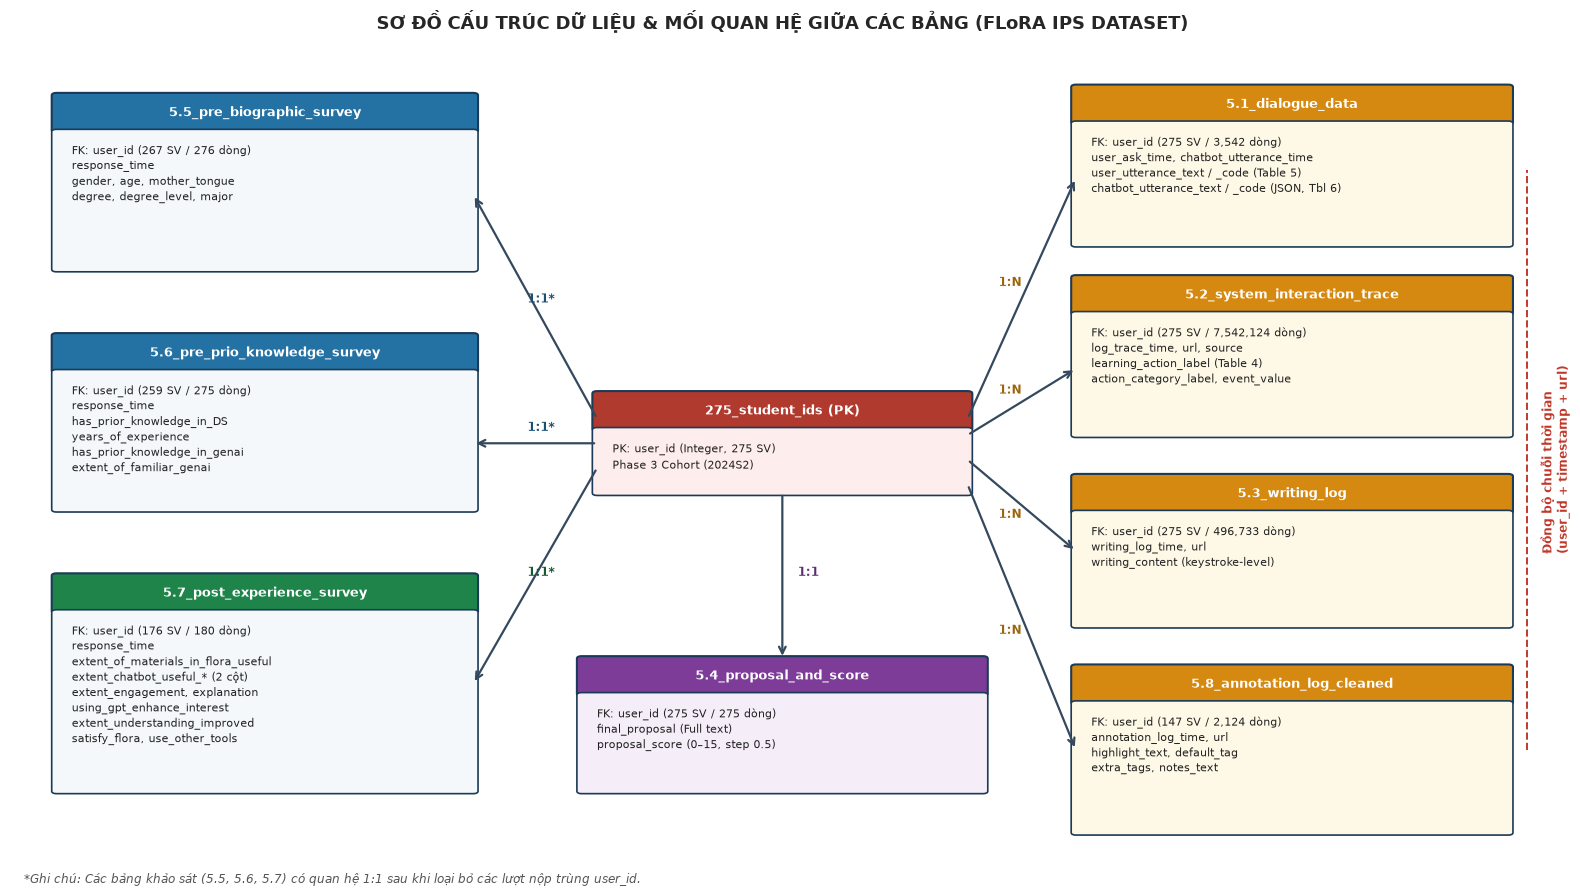

In [8]:
# Vẽ Sơ đồ cấu trúc dữ liệu (Entity Relationship Diagram) trực tiếp trong Notebook
fig, ax = plt.subplots(figsize=(16, 9))
ax.set_xlim(0, 100)
ax.set_ylim(0, 100)
ax.axis('off')

def draw_table(ax, x, y, w, h, title, cols, header_color='#2c5f8a', body_color='#f4f8fb'):
    # Header
    ax.add_patch(patches.FancyBboxPatch((x, y + h - 4.2), w, 4.2, boxstyle="round,pad=0.3",
                                        facecolor=header_color, edgecolor='#1b3a57', linewidth=1.5))
    ax.text(x + w/2, y + h - 2.1, title, color='white', fontsize=9.5, fontweight='bold', ha='center', va='center')
    # Body
    ax.add_patch(patches.FancyBboxPatch((x, y), w, h - 4.4, boxstyle="round,pad=0.3",
                                        facecolor=body_color, edgecolor='#1b3a57', linewidth=1.2))
    ax.text(x + 1.0, y + h - 5.8, "\n".join(cols), color='#222222', fontsize=8.2, ha='left', va='top', linespacing=1.35)

# Bảng trung tâm
draw_table(ax, 38, 46, 24, 12, "275_student_ids (PK)",
           ["PK: user_id (Integer, 275 SV)", "Phase 3 Cohort (2024S2)"],
           header_color='#b03a2e', body_color='#fdedec')

# Nhánh Trái: Khảo sát (Phase 1 & Phase 4)
draw_table(ax, 3, 73, 27, 21, "5.5_pre_biographic_survey",
           ["FK: user_id (267 SV / 276 dòng)", "response_time", "gender, age, mother_tongue", "degree, degree_level, major"],
           header_color='#2471a3')
draw_table(ax, 3, 44, 27, 21, "5.6_pre_prio_knowledge_survey",
           ["FK: user_id (259 SV / 275 dòng)", "response_time", "has_prior_knowledge_in_DS", "years_of_experience", "has_prior_knowledge_in_genai", "extent_of_familiar_genai"],
           header_color='#2471a3')
draw_table(ax, 3, 10, 27, 26, "5.7_post_experience_survey",
           ["FK: user_id (176 SV / 180 dòng)", "response_time", "extent_of_materials_in_flora_useful", "extent_chatbot_useful_* (2 cột)", "extent_engagement, explanation", "using_gpt_enhance_interest", "extent_understanding_improved", "satisfy_flora, use_other_tools"],
           header_color='#1e8449')

# Nhánh Dưới: Kết quả học tập (Phase 3 Outcome)
draw_table(ax, 37, 10, 26, 16, "5.4_proposal_and_score",
           ["FK: user_id (275 SV / 275 dòng)", "final_proposal (Full text)", "proposal_score (0–15, step 0.5)"],
           header_color='#7d3c98', body_color='#f5eef8')

# Nhánh Phải: Process Traces (Phase 3 - 1:N)
draw_table(ax, 69, 76, 28, 19, "5.1_dialogue_data",
           ["FK: user_id (275 SV / 3,542 dòng)", "user_ask_time, chatbot_utterance_time", "user_utterance_text / _code (Table 5)", "chatbot_utterance_text / _code (JSON, Tbl 6)"],
           header_color='#d68910', body_color='#fef9e7')
draw_table(ax, 69, 53, 28, 19, "5.2_system_interaction_trace",
           ["FK: user_id (275 SV / 7,542,124 dòng)", "log_trace_time, url, source", "learning_action_label (Table 4)", "action_category_label, event_value"],
           header_color='#d68910', body_color='#fef9e7')
draw_table(ax, 69, 30, 28, 18, "5.3_writing_log",
           ["FK: user_id (275 SV / 496,733 dòng)", "writing_log_time, url", "writing_content (keystroke-level)"],
           header_color='#d68910', body_color='#fef9e7')
draw_table(ax, 69, 5, 28, 20, "5.8_annotation_log_cleaned",
           ["FK: user_id (147 SV / 2,124 dòng)", "annotation_log_time, url", "highlight_text, default_tag", "extra_tags, notes_text"],
           header_color='#d68910', body_color='#fef9e7')

# Vẽ các đường nối
arrow_kw = dict(arrowstyle='->', color='#34495e', lw=1.6, shrinkA=2, shrinkB=2)
ax.annotate('', xy=(30, 82), xytext=(38, 55), arrowprops=arrow_kw)
ax.annotate('', xy=(30, 52), xytext=(38, 52), arrowprops=arrow_kw)
ax.annotate('', xy=(30, 23), xytext=(38, 49), arrowprops=arrow_kw)
ax.annotate('', xy=(50, 26), xytext=(50, 46), arrowprops=arrow_kw)
ax.annotate('', xy=(69, 84), xytext=(62, 55), arrowprops=arrow_kw)
ax.annotate('', xy=(69, 61), xytext=(62, 53), arrowprops=arrow_kw)
ax.annotate('', xy=(69, 39), xytext=(62, 50), arrowprops=arrow_kw)
ax.annotate('', xy=(69, 15), xytext=(62, 47), arrowprops=arrow_kw)

# Nhãn quan hệ
ax.text(33.5, 69, "1:1*", fontsize=8.5, fontweight='bold', color='#1b4f72')
ax.text(33.5, 53.5, "1:1*", fontsize=8.5, fontweight='bold', color='#1b4f72')
ax.text(33.5, 36, "1:1*", fontsize=8.5, fontweight='bold', color='#145a32')
ax.text(51, 36, "1:1", fontsize=8.5, fontweight='bold', color='#5b2c6f')
ax.text(64, 71, "1:N", fontsize=8.5, fontweight='bold', color='#9c640c')
ax.text(64, 58, "1:N", fontsize=8.5, fontweight='bold', color='#9c640c')
ax.text(64, 43, "1:N", fontsize=8.5, fontweight='bold', color='#9c640c')
ax.text(64, 29, "1:N", fontsize=8.5, fontweight='bold', color='#9c640c')

# Đường liên kết đồng bộ thời gian giữa 4 bảng Phase 3
ax.plot([98.2, 98.2], [15, 85], linestyle='--', color='#c0392b', lw=1.4)
ax.text(99.0, 50, "Đồng bộ chuỗi thời gian\n(user_id + timestamp + url)", rotation=90,
        fontsize=8.5, color='#c0392b', va='center', ha='left', fontweight='bold')

plt.title("SƠ ĐỒ CẤU TRÚC DỮ LIỆU & MỐI QUAN HỆ GIỮA CÁC BẢNG (FLoRA IPS DATASET)",
          fontsize=13, fontweight='bold', pad=12)
plt.figtext(0.02, 0.01, "*Ghi chú: Các bảng khảo sát (5.5, 5.6, 5.7) có quan hệ 1:1 sau khi loại bỏ các lượt nộp trùng user_id.",
            fontsize=8.5, style='italic', color='#555555')
plt.tight_layout()
plt.show()

# 5. Bảng từ điển dữ liệu (Data Dictionary) & Codebook Tiếng Việt

### 5.1. Bảng `5.1_dialogue data.xlsx` (Nhật ký hội thoại Sinh viên – GPT-4o | 3,542 dòng)
| Tên trường | Ý nghĩa / Mô tả (Tiếng Việt) | Kiểu dữ liệu / Miền giá trị | Missing |
| :--- | :--- | :--- | :---: |
| `user_id` | Mã định danh ẩn danh duy nhất của sinh viên (Khóa ngoại) | Integer | 0% |
| `user_ask_time` | Mốc thời gian sinh viên gửi câu hỏi cho chatbot | Timestamp | 0% |
| `user_utterance_text` | Nội dung văn bản câu hỏi của sinh viên | String | 0% |
| `user_utterance_code` | Mã gán nhãn ý định câu hỏi của sinh viên (11 nhãn ở Table 5) | String (Categorical) | 0% |
| `chatbot_utterance_time` | Mốc thời gian chatbot trả về phản hồi | Timestamp | 0% |
| `chatbot_utterance_text` | Nội dung phản hồi của chatbot, lưu dạng danh sách JSON các phân đoạn văn bản | String (JSON List) | 0% |
| `chatbot_utterance_code` | Danh sách mã phân loại tương ứng từng phân đoạn phản hồi của chatbot (7 nhãn ở Table 6) | String (JSON List) | 0% |

---

### 5.2. Bảng `5.2_system_interaction_trace_data_1 & _2.xlsx` (Dấu vết tương tác hệ thống | 7,542,124 dòng)
| Tên trường | Ý nghĩa / Mô tả (Tiếng Việt) | Kiểu dữ liệu / Miền giá trị | Missing |
| :--- | :--- | :--- | :---: |
| `user_id` | Mã định danh ẩn danh của sinh viên | Integer | 0% |
| `log_trace_time` | Mốc thời gian phát sinh sự kiện tương tác | Timestamp | 0% |
| `url` | Đường dẫn URL trang web nơi sự kiện được kích hoạt | String | 0% |
| `source` | Nguồn phát sinh sự kiện (vd: `TIMER`, `MOUSE`, `KEYBOARD`, `CLICK`) | String | 0% |
| `learning_action_label` | Nhãn hành động học tập chi tiết được ánh xạ tự động qua luật (23 nhãn ở Table 4) | String (Categorical) | 0% |
| `action_category_label` | Nhóm hành động học tập tổng quát (8 nhóm ở Table 4: `START`, `INSTRUCTION`, `READING`, `ESSAY`, `ANNOTATION`, `CHATBOT`, `NAVIGATION`, `OFF_TASK`) | String (Categorical) | 0% |
| `event_value` | Siêu dữ liệu bổ sung của sự kiện theo định dạng `<EVENT_KEY>:::<value>`; rỗng nếu không có | String (Optional) | ~7.4% |

---

### 5.3. Bảng `5.3_writing_log.xlsx` (Nhật ký quá trình viết | 496,733 dòng)
| Tên trường | Ý nghĩa / Mô tả (Tiếng Việt) | Kiểu dữ liệu / Miền giá trị | Missing |
| :--- | :--- | :--- | :---: |
| `user_id` | Mã định danh ẩn danh của sinh viên | Integer | 0% |
| `writing_log_time` | Mốc thời gian ghi nhận bản ghi viết | Timestamp | 0% |
| `url` | Đường dẫn URL trang web ghi nhận hoạt động viết | String | 0% |
| `writing_content` | Toàn bộ văn bản bài viết hiện tại được lưu lại sau mỗi thao tác gõ phím (`keystroke`) | String | 0% |

---

### 5.4. Bảng `5.4_proposal_and_score.xlsx` (Sản phẩm đề xuất & Điểm số | 275 dòng)
| Tên trường | Ý nghĩa / Mô tả (Tiếng Việt) | Kiểu dữ liệu / Miền giá trị | Missing |
| :--- | :--- | :--- | :---: |
| `user_id` | Mã định danh ẩn danh của sinh viên | Integer | 0% |
| `final_proposal` | Toàn văn bản đề xuất dự án khoa học dữ liệu cuối cùng của sinh viên | String | 0% |
| `proposal_score` | **Biến kết quả đầu ra**: Tổng điểm rubric do giảng viên chấm (5 tiêu chí × 3 điểm; chiếm 15% điểm môn học) | Numeric (0–15, bước 0.5) | 0% |

---

### 5.5. Bảng `5.5_pre-task_biographic_survey.xlsx` (Khảo sát nhân khẩu học Phase 1 | 276 dòng, 267 SV)
| Tên trường | Ý nghĩa / Mô tả (Tiếng Việt) | Kiểu dữ liệu / Miền giá trị | Missing |
| :--- | :--- | :--- | :---: |
| `user_id` | Mã định danh ẩn danh của sinh viên | Integer | 0% |
| `response_time` | Thời điểm hoàn thành khảo sát | DateTime (`DD/MM/YYYY HH:MM:SS`) | 0% |
| `gender` | Q1: Giới tính (`Woman`; `Man`; `Non-binary / gender diverse`; `My gender identity isn't listed`; `Prefer not to say`; `No answer`) | Single-select Categorical | 0.7% |
| `age` | Q2: Tuổi (tính theo năm) | Numeric (Integer) | 0.3% |
| `mother_tongue` | Q3: Ngôn ngữ mẹ đẻ | Free text | 0.7% |
| `degree` | Q4: Bậc học (`Bachelor`; `Master`; `Others`; `No answer`) | Single-select Categorical | 1.0% |
| `degree_level` | Q5: Năm học hiện tại (`Year 1`–`Year 4`; `Others`; `No answer`) | Single-select Categorical | 2.1% |
| `major` | Q6: Chuyên ngành học (vd: `Information Technology`) | Free text | 0.3% |

---

### 5.6. Bảng `5.6_pre-prio_knowledge_survey.xlsx` (Khảo sát kiến thức nền Phase 1 | 275 dòng, 259 SV)
| Tên trường | Ý nghĩa / Mô tả (Tiếng Việt) | Kiểu dữ liệu / Miền giá trị | Missing |
| :--- | :--- | :--- | :---: |
| `user_id` | Mã định danh ẩn danh của sinh viên | Integer | 0% |
| `response_time` | Thời điểm hoàn thành khảo sát | Timestamp | 0% |
| `has_prior_knowledge_in_DS` | Q1: Đã có kiến thức/kinh nghiệm về Khoa học dữ liệu chưa (`Yes`/`No`/`No answer`) | Single-select Categorical | 7.3% |
| `years_of_experience` | Q2: Số năm kinh nghiệm DS (câu hỏi điều kiện khi Q1 = `Yes`) | Numeric (Integer) | 56.3% |
| `has_prior_knowledge_in_genai` | Q3: Đã có kiến thức/kinh nghiệm về công cụ GenAI như ChatGPT/GPT-4 chưa (`Yes`/`No`/`No answer`) | Single-select Categorical | 3.8% |
| `extent_of_familiar_genai` | Q4: Mức độ quen thuộc với GenAI (điều kiện khi Q3 = `Yes`; `1 = Very unfamiliar` $\rightarrow$ `5 = Very familiar`) | 5-point Likert (Ordinal) | 6.6% |

---

### 5.7. Bảng `5.7_post-experience_using_platform_survey.xlsx` (Khảo sát trải nghiệm Phase 4 | 180 dòng, 176 SV)
| Tên trường | Ý nghĩa / Mô tả (Tiếng Việt) | Kiểu dữ liệu / Miền giá trị | Missing |
| :--- | :--- | :--- | :---: |
| `user_id` | Mã định danh ẩn danh của sinh viên | Integer | 0% |
| `response_time` | Thời điểm hoàn thành khảo sát | Timestamp | 0% |
| `extent_of_materials_in_flora_useful` | Q1: Mức độ hữu ích của tài liệu trên FLoRA để tìm chủ đề (`1 = Very unuseful` $\rightarrow$ `5 = Very useful`) | 5-point Likert | 1.6% |
| `extent_chatbot_useful_for_finding_topic` | Q2: Mức độ hữu ích của chatbot GPT để tìm chủ đề (`1 = Very unuseful` $\rightarrow$ `5 = Very useful`) | 5-point Likert | 2.2% |
| `extent_chatbot_useful_for_finish_assignment` | Q3: Mức độ hữu ích của chatbot GPT để hoàn thành bài tập (`1 = Very unuseful` $\rightarrow$ `5 = Very useful`) | 5-point Likert | 1.1% |
| `extent_engagement` | Q4: Mức độ gắn kết/tham gia dùng chatbot (`1 = Disengaged` $\rightarrow$ `5 = Highly engaged`) | 5-point Likert | 0.5% |
| `explanation` | Q5: Lý do không tương tác với chatbot GPT (nếu có) | Free text | 88.0% |
| `using_gpt_enhance_interest` | Q6: Tương tác với chatbot giúp tăng hứng thú môn học (`1 = Strongly disagree` $\rightarrow$ `5 = Strongly agree`) | 5-point Likert | 1.6% |
| `extent_understanding_of_subject_improved` | Q7: Mức độ cải thiện hiểu biết môn học sau khi dùng FLoRA (`1 = No improvement` $\rightarrow$ `5 = Significant improvement`) | 5-point Likert | 1.6% |
| `satisfy_flora` | Q8: Mức độ hài lòng chung với nền tảng FLoRA (`1 = Very dissatisfied` $\rightarrow$ `5 = Very satisfied`) | 5-point Likert | 2.7% |
| `use_other_tools` | Q9: Có cần dùng công cụ ngoài (vd: Google) để tìm chủ đề/thông tin không; nêu tên công cụ | Free text | 29.0% |

---

### 5.8. Bảng `5.8_annotation_log_cleaned.xlsx` (Nhật ký đánh dấu & ghi chú | 2,124 dòng, 147 SV)
| Tên trường | Ý nghĩa / Mô tả (Tiếng Việt) | Kiểu dữ liệu / Miền giá trị | Missing |
| :--- | :--- | :--- | :---: |
| `user_id` | Mã định danh ẩn danh của sinh viên | Integer | 0% |
| `annotation_log_time` | Thời điểm lưu ghi chú/đánh dấu | Timestamp | 0% |
| `url` | Đường dẫn URL trang đọc nơi tạo ghi chú | String | 0% |
| `highlight_text` | Đoạn văn bản sinh viên bôi đậm/đánh dấu | String | 0% |
| `default_tag` | Thẻ mặc định của hệ thống (1 trong 5 nhãn, vd: `important`, `interesting`) | String (Categorical) | 0% |
| `extra_tags` | Thẻ tùy chỉnh do sinh viên tự tạo (phân cách bằng dấu `;`, tùy chọn) | String (Optional) | — |
| `notes_text` | Nội dung ghi chú dạng văn bản thuần (tùy chọn) | String (Optional) | — |

---

### 5.9. Tóm tắt Bộ mã phân loại (Codebook chuẩn trong bài báo)
* **Codebook Hành động học tập (`Table 4` - 8 nhóm, 23 hành động):** `START` (`START_TASK`), `INSTRUCTION` (`TASK_REQUIREMENT`), `READING` (`READING_MATERIALS`, `REREADING_MATERIALS`), `ESSAY` (`OPEN_ESSAY`, `WRITE_ESSAY`, `PASTE_TEXT_ESSAY`, `SAVE_ESSAY`, `CLOSE_ESSAY`), `ANNOTATION` (`CREATE_NOTE`, `CREATE_HIGHLIGHT`, `READ_ANNOTATION`, `LABEL_ANNOTATION`, `EDIT_ANNOTATION`, `DELETE_ANNOTATION`, `SEARCH_ANNOTATION`, `CLOSE_ANNOTATION`), `CHATBOT` (`OPEN_CHATBOT`, `ASK_CHATBOT`, `READ_FEEDBACK_CHATBOT`, `CLOSE_CHATBOT`), `NAVIGATION` (`PAGE_NAVIGATION` <6s, `TABLE_OF_CONTENT`, `TRY_OUT_TOOLS` <3s), `OFF_TASK` (không hoạt động >5 phút).
* **Codebook Ý định sinh viên (`Table 5` - 11 mã, Cohen's $\kappa = 0.92$):** Nhóm *Idea Exploration* gồm 6 mã (`Knowledge`: hỏi kiến thức thực tế cố định; `Judgement`: hỏi đánh giá đa chiều/lý luận; `Preference`: xin ý kiến chủ quan; `Provide Context`: cung cấp bối cảnh; `Revise`: sửa/hỏi lại do chưa hài lòng; `Inspire`: hỏi nối tiếp từ gợi ý của bot), cùng `Task Clarification`, `Writing Advice`, `Interpret`, `Chitchat`, `Others`.
* **Codebook Phản hồi của Chatbot (`Table 6` - 7 mã, gán đa nhãn JSON):** Nhóm *Answer* gồm `Fact` (kiến thức khách quan), `Suggestion` (gợi ý/ví dụ trung lập), `Critique` (đánh giá/nhận xét chủ quan), cùng `Clarify`, `No Answer`, `Chitchat`, `Others`.

# 6. Bảng thuật ngữ chuyên ngành (Glossary)

| Thuật ngữ (Tiếng Anh) | Tiếng Việt | Giải thích & Ngữ cảnh sử dụng (Dataset + [12], [17], [32/33]) |
| :--- | :--- | :--- |
| **Information Problem Solving (IPS)** | Giải quyết vấn đề thông tin | Năng lực đa giai đoạn gồm: xác định vấn đề, tìm kiếm, đánh giá, xử lý và tổng hợp thông tin thành sản phẩm học thuật. |
| **Information-Seeking Behavior (ISB)** ([12]) | Hành vi tìm kiếm thông tin | Cách người học tìm và kiểm chứng thông tin; [12] so sánh giữa tìm kiếm Web truyền thống (từ khóa) và tìm kiếm qua GenAI (hội thoại lặp). |
| **Conversational Information Seeking (CIS)** | Tìm kiếm thông tin qua hội thoại | Mô hình tìm kiếm bằng đối thoại nhiều lượt, làm cơ sở lý thuyết xây dựng codebook Table 5 & 6. |
| **Self-Regulated Learning (SRL)** ([32], [33]) | Học tập tự điều chỉnh | Quá trình người học chủ động lập kế hoạch, giám sát và điều chỉnh chiến lược nhận thức/siêu nhận thức trong môi trường học số. |
| **FLoRA Engine** ([32], [33]) | Nền tảng FLoRA | Môi trường học tập tích hợp Moodle gồm công cụ đọc, ghi chú, soạn thảo và chatbot GPT-4o, thu thập dấu vết tương tác ở mức sự kiện. |
| **Trace Data / Learning Action Logs** | Dữ liệu dấu vết / Nhật ký hành động | Log thô (click, chuột, phím, chuyển trang) được ánh xạ qua luật (action library) thành nhãn hành động học tập (`Table 4`). |
| **Dwell Time & Off-Task** | Thời gian dừng trang & Rời nhiệm vụ | Thời gian ở lại trang (<6 giây gán là `PAGE_NAVIGATION`; không hoạt động >5 phút gán là `OFF_TASK`). |
| **Keystroke-Level Writing Logs** | Nhật ký viết mức gõ phím | Bản ghi nội dung văn bản sau từng phím gõ (`5.3`), giúp phân tích nhịp viết, viết ngắt quãng và chỉnh sửa. |
| **Scaffolding / Relational Feedback** ([17], [32]) | Phản hồi bắc giàn / mang tính tương tác | Phản hồi hỗ trợ định hướng thay vì làm hộ bài; [17] đề xuất khung đánh giá khả năng LLM đặc trưng hóa các loại phản hồi. |
| **Cognitive Offloading / Over-reliance** | Phó thác nhận thức / Lệ thuộc AI | Hành vi lạm dụng AI, ví dụ chuỗi `ASK_CHATBOT` $\rightarrow$ `PASTE_TEXT_ESSAY` ngay lập tức mà thiếu bước đọc hiểu và đánh giá. |
| **Metacognitive Monitoring** | Giám sát siêu nhận thức | Khả năng tự kiểm tra, đối chiếu thông tin; thể hiện qua chuỗi `READ_FEEDBACK_CHATBOT` $\rightarrow$ đánh giá/ghi chú $\rightarrow$ tự viết `WRITE_ESSAY`. |
| **Multi-Label JSON Annotation** | Gán đa nhãn dạng JSON | Một câu trả lời của GPT-4o thường kết hợp nhiều chức năng (`Fact` + `Suggestion` + `Critique`), nên được tách đoạn và lưu thành mảng JSON. |
| **Cohen's Kappa ($\kappa$)** | Hệ số đồng thuận Cohen's Kappa | Chỉ số đo độ tin cậy giữa các người gán nhãn độc lập (đạt $\kappa = 0.92$ trên tập hiệu chuẩn 400 lượt hội thoại). |
| **Cosine Similarity (`text-embedding-3-small`)** | Độ tương đồng cô-sin ngữ nghĩa | Dùng để so sánh văn bản viết trên FLoRA và bài nộp Moodle (loại bỏ các bài có độ tương đồng $< 0.85$). |

# 7. Thống kê mô tả cơ bản & Trực quan hóa

### 7.1. Kết quả học tập (`5.4_proposal_and_score`)

--- THỐNG KÊ MÔ TẢ ĐIỂM SỐ & ĐỘ DÀI BÀI PROPOSAL (N = 275) ---


,count,mean,std,min,25%,50%,75%,max
proposal_score,275.0,11.81,1.99,0.0,10.5,12.0,13.5,15.0
word_count,275.0,696.80,161.90,64.0,629.5,689.0,762.5,1710.0


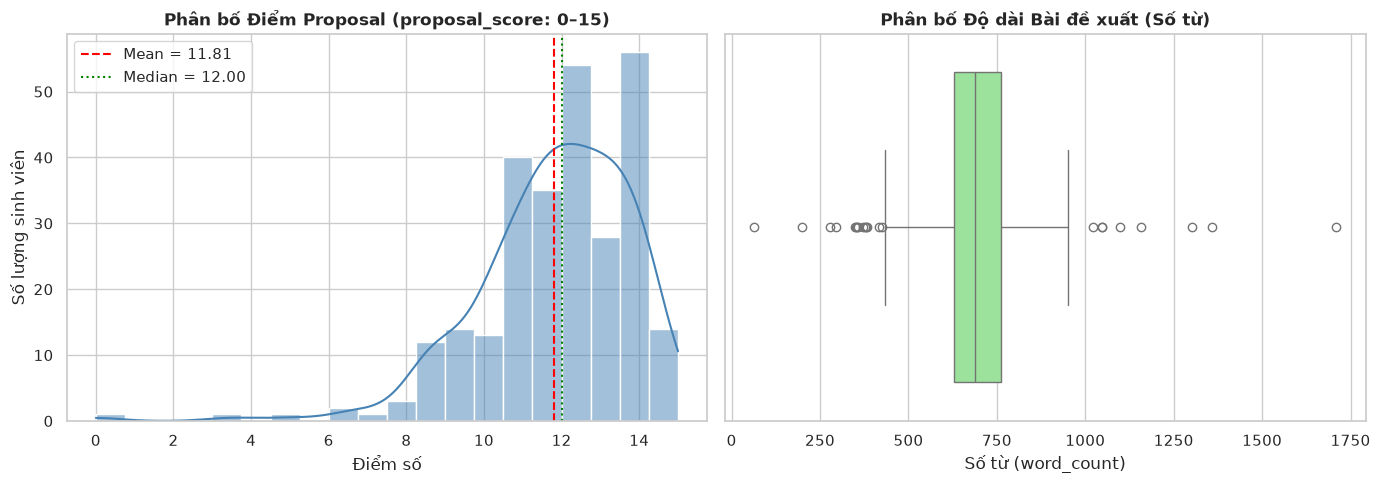

In [9]:
# Tính thêm số từ của bài proposal
proposal['word_count'] = proposal['final_proposal'].fillna('').apply(lambda x: len(str(x).split()))

print("--- THỐNG KÊ MÔ TẢ ĐIỂM SỐ & ĐỘ DÀI BÀI PROPOSAL (N = 275) ---")
display(proposal[['proposal_score', 'word_count']].describe().round(2).T)

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
sns.histplot(proposal['proposal_score'], bins=20, kde=True, color='steelblue', ax=axes[0])
axes[0].axvline(proposal['proposal_score'].mean(), color='red', linestyle='--',
                label=f"Mean = {proposal['proposal_score'].mean():.2f}")
axes[0].axvline(proposal['proposal_score'].median(), color='green', linestyle=':',
                label=f"Median = {proposal['proposal_score'].median():.2f}")
axes[0].set_title('Phân bố Điểm Proposal (proposal_score: 0–15)', fontweight='bold')
axes[0].set_xlabel('Điểm số')
axes[0].set_ylabel('Số lượng sinh viên')
axes[0].legend()

sns.boxplot(x=proposal['word_count'], color='lightgreen', ax=axes[1])
axes[1].set_title('Phân bố Độ dài Bài đề xuất (Số từ)', fontweight='bold')
axes[1].set_xlabel('Số từ (word_count)')

plt.tight_layout()
plt.show()

### 7.2. Thống kê Khảo sát trước & sau tác vụ (`5.5`, `5.6`, `5.7` - sau khi lọc trùng `user_id`)

Sau khi lọc trùng: 5.5 = 267 SV | 5.6 = 259 SV | 5.7 = 176 SV


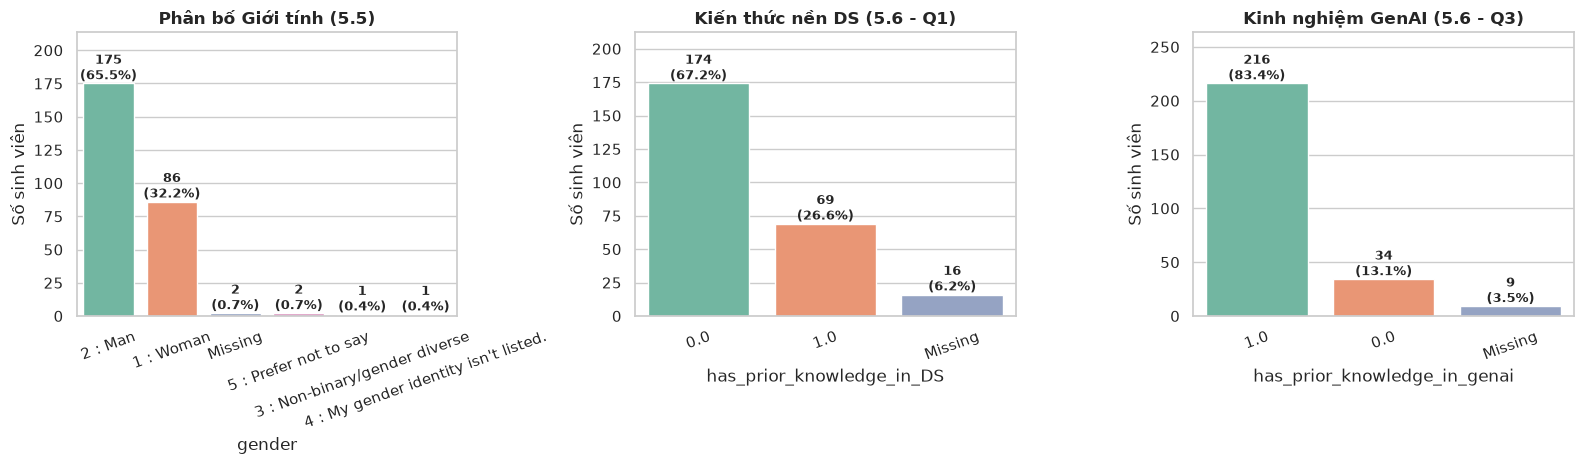


--- THỐNG KÊ MÔ TẢ KHẢO SÁT SAU TÁC VỤ (5.7 - THANG LIKERT 1–5) ---
Mẫu giá trị Likert 5.7: <StringArray>
['3 : Neutral', '2 : Unuseful', '4 : Useful', '1 : Very unuseful', '5 : Very useful']
Length: 5, dtype: str
Giá trị duy nhất sau khi parse:
extent_of_materials_in_flora_useful: [3. 2. 4. 1. 5.]
extent_chatbot_useful_for_finding_topic: [4. 3. 5. 1. 2.]
extent_chatbot_useful_for_finish_assignment: [4. 3. 1. 5. 2.]
extent_engagement: [5. 3. 2. 4. 1.]
using_gpt_enhance_interest: [5. 3. 1. 4. 2.]
extent_understanding_of_subject_improved: [4. 3. 1. 5. 2.]
satisfy_flora: [4. 3. 2. 5. 1.]


,count,mean,std,min,50%,max
extent_of_materials_in_flora_useful,173.0,3.98,1.02,1.0,4.0,5.0
extent_chatbot_useful_for_finding_topic,172.0,3.90,1.01,1.0,4.0,5.0
extent_chatbot_useful_for_finish_assignment,174.0,3.96,0.99,1.0,4.0,5.0
extent_engagement,175.0,3.69,0.91,1.0,4.0,5.0
using_gpt_enhance_interest,173.0,3.91,0.88,1.0,4.0,5.0
extent_understanding_of_subject_improved,173.0,3.78,0.95,1.0,4.0,5.0
satisfy_flora,171.0,4.06,0.82,1.0,4.0,5.0


In [14]:
# Lọc trùng user_id giữ bản ghi mới nhất theo thời gian hoàn thành
def dedup_survey(df):
    tmp = df.copy()
    tmp['_dt'] = pd.to_datetime(tmp['response_time'], dayfirst=True, errors='coerce')
    return tmp.sort_values('_dt').drop_duplicates('user_id', keep='last').drop(columns=['_dt'])

pre_bio_clean  = dedup_survey(pre_bio)
pre_know_clean = dedup_survey(pre_know)
post_clean     = dedup_survey(post_survey)

print(f"Sau khi lọc trùng: 5.5 = {len(pre_bio_clean)} SV | 5.6 = {len(pre_know_clean)} SV | 5.7 = {len(post_clean)} SV")

# Biểu đồ Giới tính (5.5) & Kiến thức nền DS/GenAI (5.6) theo style barplot có % của OULAD
fig, axes = plt.subplots(1, 3, figsize=(16, 4.8))

for ax, (series, title) in zip(axes, [
    (pre_bio_clean['gender'].fillna('Missing'), 'Phân bố Giới tính (5.5)'),
    (pre_know_clean['has_prior_knowledge_in_DS'].fillna('Missing'), 'Kiến thức nền DS (5.6 - Q1)'),
    (pre_know_clean['has_prior_knowledge_in_genai'].fillna('Missing'), 'Kinh nghiệm GenAI (5.6 - Q3)')
]):
    vc = series.value_counts()
    sns.barplot(x=vc.index, y=vc.values, palette='Set2', ax=ax)
    total = vc.sum()
    for p in ax.patches:
        h = p.get_height()
        ax.annotate(f"{int(h)}\n({h/total*100:.1f}%)",
                    (p.get_x() + p.get_width()/2, h), ha='center', va='bottom', fontsize=9, fontweight='bold')
    ax.set_title(title, fontweight='bold')
    ax.set_ylabel('Số sinh viên')
    ax.set_ylim(0, vc.max() * 1.22)
    ax.tick_params(axis='x', rotation=20)

plt.tight_layout()
plt.show()

# Thống kê mô tả các thang đo Likert ở Khảo sát sau tác vụ (5.7)
likert_cols = [
    'extent_of_materials_in_flora_useful', 'extent_chatbot_useful_for_finding_topic',
    'extent_chatbot_useful_for_finish_assignment', 'extent_engagement',
    'using_gpt_enhance_interest', 'extent_understanding_of_subject_improved', 'satisfy_flora'
]
print("\n--- THỐNG KÊ MÔ TẢ KHẢO SÁT SAU TÁC VỤ (5.7 - THANG LIKERT 1–5) ---")
# Kiểm tra nhanh các giá trị duy nhất trước khi ép kiểu
print("Mẫu giá trị Likert 5.7:", post_clean[likert_cols[0]].dropna().unique()[:10])

def parse_likert(series):
    # Nếu là số sẵn thì giữ nguyên; nếu dạng "4 = Useful" thì tách số đầu; nếu text thuần thì cần map thêm
    s = series.astype(str).str.strip()
    num = pd.to_numeric(s.str.extract(r'^(\d)')[0], errors='coerce')
    return num

likert_num = post_clean[likert_cols].apply(parse_likert)
# Nếu num vẫn bị NaN do file lưu toàn chữ (vd: "Very useful"), in unique() ra để viết dict map 1..5!
print("Giá trị duy nhất sau khi parse:")
for col in likert_cols:
    print(f"{col}: {likert_num[col].dropna().unique()}")
display(likert_num.describe().round(2).T[['count', 'mean', 'std', 'min', '50%', 'max']])

### 7.3. Tương tác Hội thoại Chatbot (`5.1_dialogue data` - Tái hiện Figure 3 & Figure 4)

Các giá trị bị parse lỗi: <StringArray>
['Answer-Fact,Answer-Suggestion', 'Answer-Critique,Answer-Suggestion', 'Answer-Fact,Others', 'Answer-Fact,Answer-Suggestion,Others', 'Answer-Suggestion,Chitchat', 'Chitchat,Others', 'Answer-Suggestion,Others', 'Clarify,Chitchat', 'Answer-Fact,Answer-Critique,Others', 'Answer-Critique,Chitchat', 'Answer-Fact,Answer-Critique,Answer-Suggestion', 'No-answer,Others', 'Answer-Suggestion,No-answer', 'Answer-Fact,Answer-Suggestion,No-answer', 'Answer-Suggestion,Clarify', 'Answer-Critique,Answer-Suggestion,Others', 'Answer-Fact,Chitchat', 'Answer-Suggestion,Chitchat,Others', 'Answer-Critique,Answer-Suggestion,Chitchat', 'Answer-Fact,Chitchat,Others']
Length: 20, dtype: str
Số lượt hỏi/SV: Mean = 12.9, Median = 11.0, Min = 2, Max = 64 (Bài báo Fig 4: Mean=12.9, Median=11.0, Min=2, Max=64)


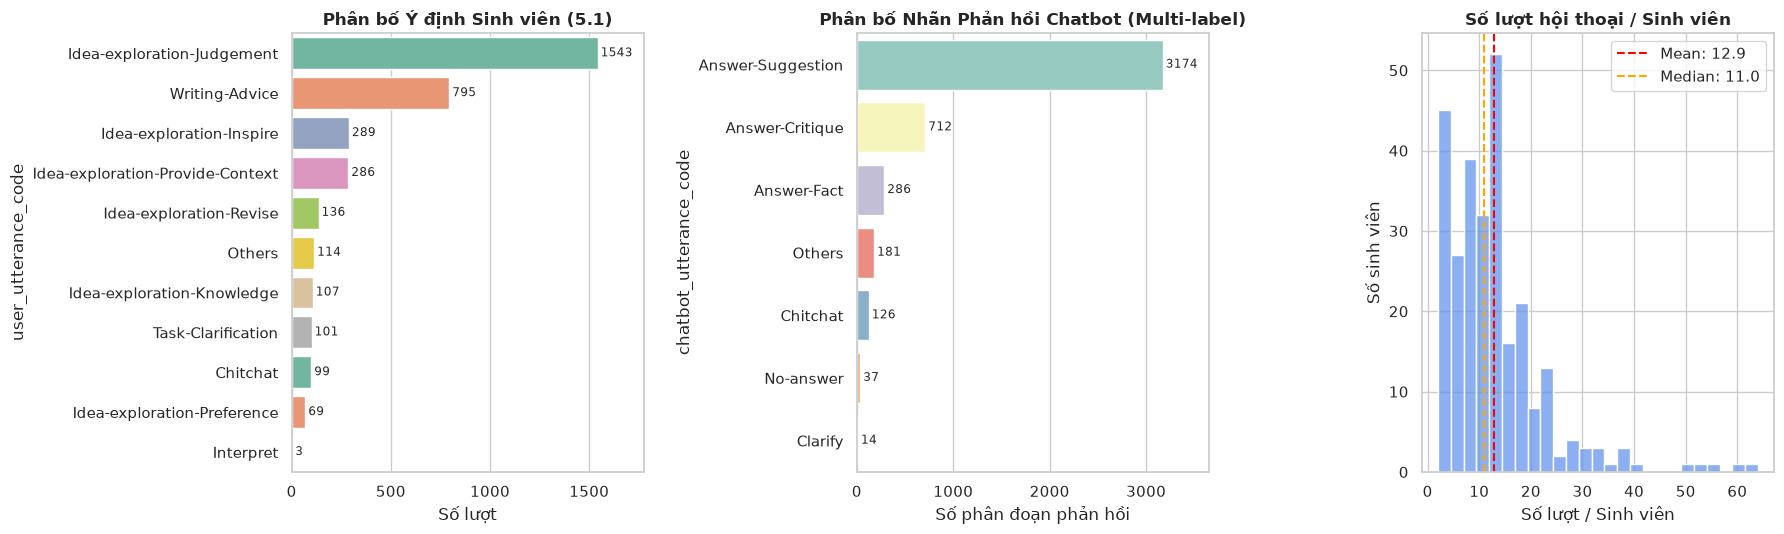

In [15]:
import re

# 1. Xem những dòng nào không nằm trong 7 nhãn chuẩn sau khi parse
valid_bot_codes = {'Answer-Fact', 'Answer-Suggestion', 'Answer-Critique', 'Clarify', 'No-answer', 'Chitchat', 'Others'}
raw_parsed = dialogue['chatbot_utterance_code'].apply(parse_code_list).explode()
print("Các giá trị bị parse lỗi:", raw_parsed[~raw_parsed.isin(valid_bot_codes)].unique())

# 2. Hàm parse an toàn (tách cả JSON list, dấu phẩy, chấm phẩy, xuống dòng, bỏ ngoặc thừa)
def parse_code_list_fixed(val):
    if pd.isna(val): 
        return []
    s = str(val).strip()
    try:
        res = json.loads(s)
        if isinstance(res, list):
            return [str(x).strip() for x in res]
    except Exception:
        pass
    # Tách theo dấu phẩy, chấm phẩy hoặc xuống dòng và dọn ngoặc/nháy
    parts = re.split(r'[,;\n]+', s.strip('[]'))
    return [p.strip().strip('"\' ') for p in parts if p.strip()]

# Tách đa nhãn của chatbot
chatbot_counts = dialogue['chatbot_utterance_code'].apply(parse_code_list_fixed).explode().value_counts()
student_counts = dialogue['user_utterance_code'].value_counts()
turns_per_user = dialogue.groupby('user_id').size()

print(f"Số lượt hỏi/SV: Mean = {turns_per_user.mean():.1f}, Median = {turns_per_user.median():.1f}, "
      f"Min = {turns_per_user.min()}, Max = {turns_per_user.max()} (Bài báo Fig 4: Mean=12.9, Median=11.0, Min=2, Max=64)")

fig, axes = plt.subplots(1, 3, figsize=(18, 5.5))

# 1. Phân bố mã câu hỏi sinh viên (Fig 3 trái)
sns.barplot(x=student_counts.values, y=student_counts.index, palette='Set2', ax=axes[0])
axes[0].set_title('Phân bố Ý định Sinh viên (5.1)', fontweight='bold')
axes[0].set_xlabel('Số lượt')
for p in axes[0].patches:
    w = p.get_width()
    axes[0].annotate(f"{int(w)}", (w + 15, p.get_y() + p.get_height()/2), va='center', fontsize=8.5)
axes[0].set_xlim(0, student_counts.max() * 1.15)

# 2. Phân bố mã trả lời chatbot (Fig 3 phải)
sns.barplot(x=chatbot_counts.values, y=chatbot_counts.index, palette='Set3', ax=axes[1])
axes[1].set_title('Phân bố Nhãn Phản hồi Chatbot (Multi-label)', fontweight='bold')
axes[1].set_xlabel('Số phân đoạn phản hồi')
for p in axes[1].patches:
    w = p.get_width()
    axes[1].annotate(f"{int(w)}", (w + 30, p.get_y() + p.get_height()/2), va='center', fontsize=8.5)
axes[1].set_xlim(0, chatbot_counts.max() * 1.15)

# 3. Phân bố số lượt hỏi trên mỗi sinh viên (Fig 4)
sns.histplot(turns_per_user, bins=25, color='cornflowerblue', ax=axes[2])
axes[2].axvline(turns_per_user.mean(), color='red', linestyle='--', label=f"Mean: {turns_per_user.mean():.1f}")
axes[2].axvline(turns_per_user.median(), color='orange', linestyle='--', label=f"Median: {turns_per_user.median():.1f}")
axes[2].set_title('Số lượt hội thoại / Sinh viên', fontweight='bold')
axes[2].set_xlabel('Số lượt / Sinh viên')
axes[2].set_ylabel('Số sinh viên')
axes[2].legend()

plt.tight_layout()
plt.show()

### 7.4. Thống kê Nhật ký Viết (`5.3`), Ghi chú (`5.8`) và Dấu vết Hệ thống (`5.2`)

--- THỐNG KÊ MÔ TẢ TẦN SUẤT HOẠT ĐỘNG QUÁ TRÌNH ---


,count,mean,std,min,25%,50%,75%,max
"Writing events / SV (5.3, N=275)",275.0,1806.30,3574.48,2.0,26.5,189.0,1720.5,31982.0
"Annotations / SV có dùng (5.8, N=147)",147.0,14.45,23.79,1.0,3.0,6.0,15.5,186.0
"System trace logs / SV (5.2, N=275)",275.0,27425.91,26299.98,950.0,10868.0,18993.0,33372.0,186511.0


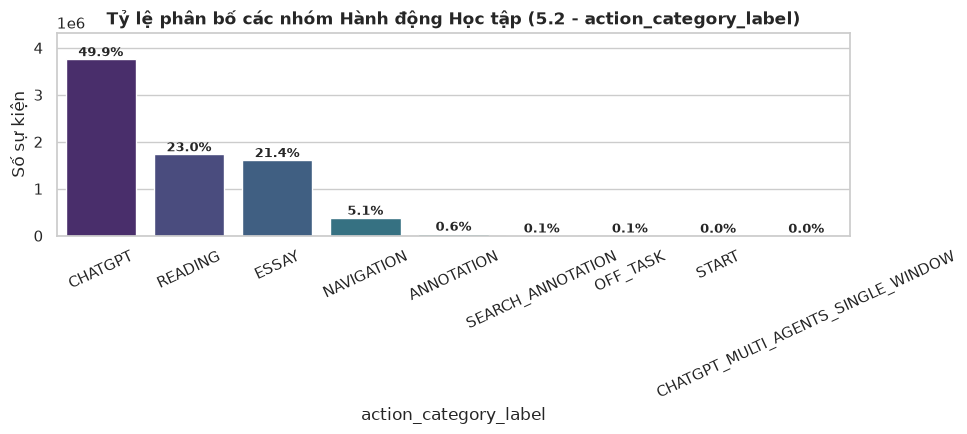

In [12]:
write_per_user = writing_log.groupby('user_id').size()
annot_per_user = annotation.groupby('user_id').size()
trace_per_user = trace_all.groupby('user_id').size()

process_summary = pd.DataFrame({
    "Writing events / SV (5.3, N=275)": write_per_user.describe(),
    "Annotations / SV có dùng (5.8, N=147)": annot_per_user.describe(),
    "System trace logs / SV (5.2, N=275)": trace_per_user.describe()
}).round(2).T
print("--- THỐNG KÊ MÔ TẢ TẦN SUẤT HOẠT ĐỘNG QUÁ TRÌNH ---")
display(process_summary)

# Phân bố 8 nhóm hành động trong 5.2_system_interaction_trace_data
cat_counts = trace_all['action_category_label'].value_counts()
plt.figure(figsize=(10, 4.5))
ax = sns.barplot(x=cat_counts.index, y=cat_counts.values, palette='viridis')
total_events = cat_counts.sum()
for p in ax.patches:
    h = p.get_height()
    ax.annotate(f"{h/total_events*100:.1f}%", (p.get_x() + p.get_width()/2, h),
                ha='center', va='bottom', fontsize=9, fontweight='bold')
plt.title('Tỷ lệ phân bố các nhóm Hành động Học tập (5.2 - action_category_label)', fontweight='bold')
plt.ylabel('Số sự kiện')
plt.xticks(rotation=25)
plt.ylim(0, cat_counts.max() * 1.15)
plt.tight_layout()
plt.show()

# 8. Đề xuất các câu hỏi nghiên cứu (Research Questions)

Dựa trên các biến hiện có và các giới hạn được chỉ ra trong bài báo (không có nhóm đối chứng, chỉ có tổng điểm `proposal_score` 0–15, `5.7` chỉ có 176 SV, `5.8` chỉ có 147 SV), dưới đây là **5 câu hỏi nghiên cứu mà dữ liệu thực sự trả lời được**:

1. **RQ1 (Chiến lược đặt câu hỏi GenAI & Kết quả học tập — gắn [12] + `5.1`, `5.4`, `5.5`, `5.6`):**
   * *Câu hỏi:* Tần suất và tỷ lệ các nhóm ý định hỏi chatbot (như `Judgement`, `Inspire`, `Revise` so với `Knowledge` hay `Writing Advice`) có mối liên hệ như thế nào đến `proposal_score`, khi kiểm soát kiến thức nền (`5.6`) và ngôn ngữ mẹ đẻ (`5.5`)?
   * *Phương pháp gợi ý:* Hồi quy tuyến tính đa biến / Phân cụm chiến lược tìm kiếm thông tin (Cluster Analysis) gắn với khung ISB [12].

2. **RQ2 (Đặc trưng phản hồi của GPT-4o & Sự chuyển hóa vào bài viết — gắn [17] + `5.1`, `5.3`, `5.4`):**
   * *Câu hỏi:* Các kiểu phản hồi đa chức năng của chatbot (`Fact`, `Suggestion`, `Critique`, `Clarify`) ảnh hưởng ra sao đến phản ứng ngay sau đó của sinh viên — tiếp tục đào sâu ý tưởng (`Inspire`/`Revise`) hay sao chép/biên tập trực tiếp vào bản thảo (`writing_log` / `final_proposal`)?
   * *Phương pháp gợi ý:* Phân tích tuần tự kết hợp tính độ tương đồng văn bản giữa `chatbot_utterance_text` và độ tăng trưởng/chỉnh sửa của `writing_content` sau mốc `chatbot_utterance_time`.

3. **RQ3 (Mẫu hình chuyển đổi SRL: Lệ thuộc nhận thức vs. Giám sát siêu nhận thức — gắn [32]/[33] + `5.2`, `5.3`, `5.4`):**
   * *Câu hỏi:* Dựa trên chuỗi `learning_action_label` theo thời gian, có thể phát hiện các mẫu hình hành vi đặc trưng cho *phó thác nhận thức* (vd: `ASK_CHATBOT` $\rightarrow$ `PASTE_TEXT_ESSAY` liên tiếp) so với *giám sát siêu nhận thức* (vd: `READ_FEEDBACK_CHATBOT` $\rightarrow$ `REREADING_MATERIALS`/`ANNOTATION` $\rightarrow$ `WRITE_ESSAY`), và sự khác biệt này tác động thế nào tới `proposal_score`?
   * *Phương pháp gợi ý:* Process Mining / Sequence Mining (TraMineR hoặc Markov transitions) theo Usage Notes (tr. 18).

4. **RQ4 (Vai trò của hành vi đọc & ghi chú chủ động — `5.8` + `5.1`, `5.4`):**
   * *Câu hỏi:* Nhóm sinh viên chủ động sử dụng công cụ đánh dấu/ghi chú (`N = 147`) có đặt câu hỏi chiều sâu (`Judgement`/`Inspire`) nhiều hơn và đạt `proposal_score` cao hơn nhóm không dùng (`N = 128`) hay không?
   * *Phương pháp gợi ý:* Kiểm định phi tham số Mann–Whitney U hoặc Propensity Score Matching (kiểm soát `5.5`, `5.6`).

5. **RQ5 (Khoảng cách giữa Nhận thức chủ quan và Hành vi thực tế — `5.7` + `5.1`, `5.2`, `5.4`):**
   * *Câu hỏi:* Cảm nhận về mức độ hữu ích, hứng thú và sự gắn kết tự đánh giá (`5.7`, `N = 176`) có tương quan thuận với tần suất tương tác thực tế (`5.1`, `5.2`) và điểm `proposal_score` (`5.4`) hay tồn tại sai lệch nhận thức ở nhóm có sử dụng công cụ bên ngoài (`use_other_tools`)?
   * *Phương pháp gợi ý:* Tương quan Spearman + phân tích phân nhóm theo `use_other_tools`.

In [13]:
# Kiểm chứng nhanh cỡ mẫu giao nhau thực tế cho 5 Câu hỏi nghiên cứu
rq_feasibility = pd.DataFrame([
    {"RQ": "RQ1 (Hội thoại + Điểm + Nền)", "Bảng giao nhau": "5.1 ∩ 5.4 ∩ 5.5 ∩ 5.6",
     "Số SV khả thi": len(set(dialogue['user_id']) & set(proposal['user_id']) & set(pre_bio_clean['user_id']) & set(pre_know_clean['user_id']))},
    {"RQ": "RQ2 (Phản hồi AI + Log viết)", "Bảng giao nhau": "5.1 ∩ 5.3 ∩ 5.4",
     "Số SV khả thi": len(set(dialogue['user_id']) & set(writing_log['user_id']) & set(proposal['user_id']))},
    {"RQ": "RQ3 (Chuỗi hành vi SRL + Viết)", "Bảng giao nhau": "5.2 ∩ 5.3 ∩ 5.4",
     "Số SV khả thi": len(set(trace_all['user_id']) & set(writing_log['user_id']) & set(proposal['user_id']))},
    {"RQ": "RQ4 (Ghi chú vs Không ghi chú)", "Bảng giao nhau": "5.8 (147) vs còn lại (128) + 5.1 + 5.4",
     "Số SV khả thi": len(valid_ids)},
    {"RQ": "RQ5 (Nhận thức Post-survey + Thực tế)", "Bảng giao nhau": "5.7 ∩ 5.1 ∩ 5.4",
     "Số SV khả thi": len(set(post_clean['user_id']) & set(dialogue['user_id']) & set(proposal['user_id']))},
])
print("--- KIỂM CHỨNG CỠ MẪU KHẢ THI CHO TỪNG CÂU HỎI NGHIÊN CỨU ---")
display(rq_feasibility)

--- KIỂM CHỨNG CỠ MẪU KHẢ THI CHO TỪNG CÂU HỎI NGHIÊN CỨU ---


,RQ,Bảng giao nhau,Số SV khả thi
0,RQ1 (Hội thoại + Điểm + Nền),5.1 ∩ 5.4 ∩ 5.5 ∩ 5.6,258
1,RQ2 (Phản hồi AI + Log viết),5.1 ∩ 5.3 ∩ 5.4,275
2,RQ3 (Chuỗi hành vi SRL + Viết),5.2 ∩ 5.3 ∩ 5.4,275
3,RQ4 (Ghi chú vs Không ghi chú),5.8 (147) vs còn lại (128) + 5.1 + 5.4,275
4,RQ5 (Nhận thức Post-survey + Thực tế),5.7 ∩ 5.1 ∩ 5.4,176
